# Mineração de Séries Temporais: Clusterização em Duas Camadas
## Sazonalidade dos Componentes do IPCA e Regimes Macroeconômicos com Ouro e Juros

> **Projeto de Mineração de Dados:** Previsão da Inflação e Identificação de Regimes Estruturais  
> **Arquitetura Metodológica:** *Two-Tier Decoupled Clustering Framework*  
> **Algoritmo Central:** Agrupamento Hierárquico Aglomerativo com critério de mínima variância de Ward (*Ward's Hierarchical Clustering*)  

---
### Objetivos da Análise:
1. **Camada 1 (Micro / Sazonal):** Mapear como os meses do ano se clusterizam segundo os subcomponentes do IPCA, desvendando os choques sazonais institucionais (educação em fevereiro, remédios em abril, safra em julho-setembro).
2. **Camada 2 (Macro / Dinâmica):** Identificar regimes de co-movimentação entre inflação ($IPCA$), aceleração de política monetária ($\Delta SELIC$) e fuga para ativos de refúgio / câmbio ($\Delta \% Ouro_{BRL}$).
3. **Camada 3 (Interação Cruzada):** Avaliar empiricamente se choques exógenos severos de ouro e juros rompem a sazonalidade biológica e regulatória típica.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.stats import chi2_contingency

sns.set_theme(style='whitegrid', palette='muted')
print('Bibliotecas importadas com sucesso!')


Bibliotecas importadas com sucesso!


## 1. Carga dos Dados e Engenharia de Atributos Macroeconômicos

Carregamos a base consolidada contendo 174 meses (2012–2026), enriquecida com a cotação do **Ouro Internacional ($GLD$)**, convertida em moeda nacional ($Ouro_{BRL} = Ouro_{USD} 	imes USDBRL$), calculando variações estacionárias e o juro real.


In [4]:
df = pd.read_csv('../Dados/df_macro_ouro.csv', parse_dates=['Date'])
print(f'Dimensões da base: {df.shape[0]} meses x {df.shape[1]} atributos.')
print('Período amostral:', df['Date'].min().strftime('%Y-%m'), 'a', df['Date'].max().strftime('%Y-%m'))
df[['Date', 'IPCA', 'SELIC', 'Delta_SELIC', 'Ouro_BRL', 'Ret_Ouro_BRL', 'Juro_Real']].head(4)


Dimensões da base: 174 meses x 38 atributos.
Período amostral: 2012-03 a 2026-08
        Date  IPCA  SELIC  Delta_SELIC    Ouro_BRL  Ret_Ouro_BRL  Juro_Real
0 2012-03-01 -0.08   0.82          NaN  295.398843           NaN       0.90
1 2012-04-01  0.55   0.71        -0.11  306.244593      3.671561       0.16
2 2012-05-01  0.48   0.74         0.03  306.621116      0.122948       0.26
3 2012-06-01 -0.31   0.64        -0.10  313.685552      2.303963       0.95


## 2. Camada 1: Clusterização da Sazonalidade dos Componentes do IPCA

Utilizamos os 7 subcomponentes desagregados de preços para isolar o padrão intra-anual:
* `IPCA_Transportes`
* `IPCA Alimentação_bebidas`
* `INPC_Habitação`
* `IPCA_Saúde_cuidados_pessoais`
* `IPCA_Vestuário`
* `IPCA_Educação`
* `IPCA_Despesas_Pessoais`

Aplicamos a padronização Z-score e o algoritmo **Hierárquico de Ward**.


In [6]:
comp_cols = ['IPCA_Transportes', 'IPCA Alimentação_bebidas', 'INPC_Habitação', 
             'IPCA_Saúde_cuidados_pessoais', 'IPCA_Vestuário', 'IPCA_Educação', 'IPCA_Despesas_Pessoais']
X1 = StandardScaler().fit_transform(df[comp_cols].dropna())

# Avaliação de métricas para diferentes valores de k
metricas_sazonal = []
for k in range(2, 7):
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X1)
    metricas_sazonal.append({
        'k': k,
        'Silhouette': round(silhouette_score(X1, labels), 3),
        'Davies-Bouldin': round(davies_bouldin_score(X1, labels), 3),
        'Calinski-Harabasz': round(calinski_harabasz_score(X1, labels), 1)
    })
pd.DataFrame(metricas_sazonal)


   k  Silhouette  Davies-Bouldin  Calinski-Harabasz
0  2       0.324           1.085               63.8
1  3       0.132           1.837               44.5
2  4       0.155           1.796               38.6
3  5       0.175           1.631               34.2
4  6       0.179           1.587               31.9


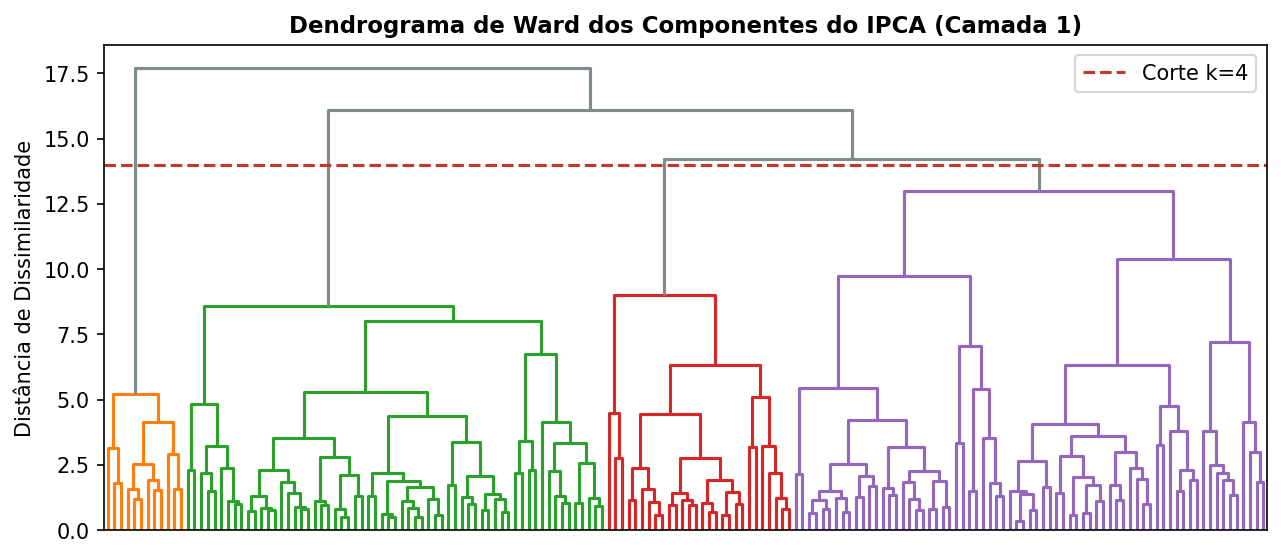

In [7]:
Z1 = linkage(X1, method='ward')
plt.figure(figsize=(10, 4.2))
dendrogram(Z1, no_labels=True, color_threshold=14, above_threshold_color='#7f8c8d')
plt.axhline(y=14, color='#c0392b', linestyle='--', linewidth=1.5, label='Corte Ótimo (k=4)')
plt.title('Dendrograma de Ward dos Componentes do IPCA (Camada 1)', fontsize=11, fontweight='bold')
plt.ylabel('Distância de Dissimilaridade (Variância)')
plt.legend(); plt.show()


### Distribuição dos Meses do Ano por Cluster Sazonal
A tabela de contingência abaixo demonstra com clareza o poder explicativo da clusterização:
* **Cluster 3:** Isola 12 dos 13 meses de **Fevereiro** da série (choque estrutural de mensalidades escolares e matrículas em *Educação*).
* **Cluster 1:** Concentra os meses de **Abril e Maio** (reajuste regulatório de remédios pela CMED).
* **Cluster 2:** Domina o período de **Julho a Outubro** (descompressão de safra agrícola e deflação em alimentos).


In [9]:
c1 = AgglomerativeClustering(n_clusters=4, linkage='ward').fit_predict(X1)
df['Cluster_Sazonal'] = c1
ct_sazonal = pd.crosstab(df['Date'].dt.month, df['Cluster_Sazonal'])
ct_sazonal.columns = [f'Cluster {c}' for c in ct_sazonal.columns]
ct_sazonal


Cluster_Sazonal   0   1   2   3
Mês do Ano                     
1                13   0   1   0
2                 1   0   1  12
3                11   0   4   0
4                 1  13   1   0
5                 1   7   7   0
6                 5   2   8   0
7                 6   1   8   0
8                 5   1   9   0
9                 3   1  10   0
10                6   1   7   0
11                8   0   6   0
12               11   2   1   0


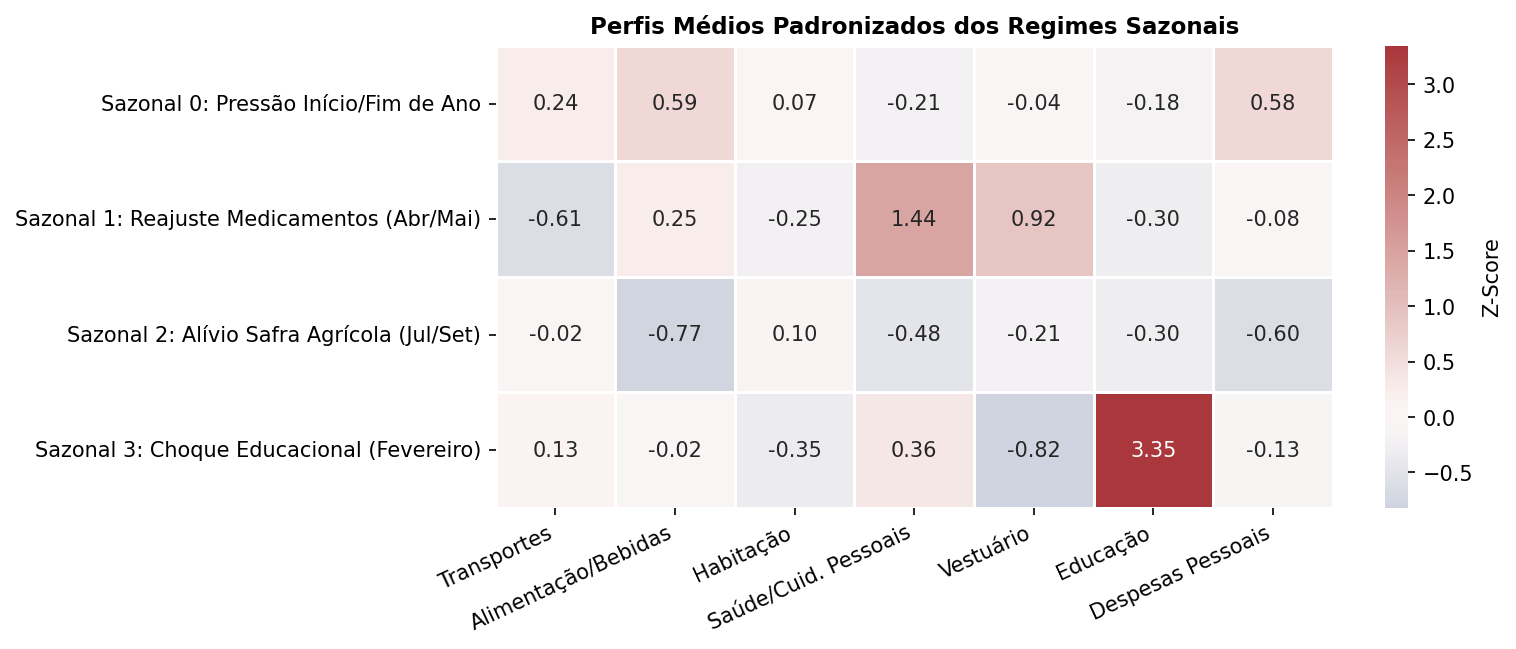

In [10]:
perfil_sazonal = pd.DataFrame(X1, columns=comp_names).groupby(c1).mean()
perfil_sazonal.index = [rotulos_sazonais[i] for i in range(4)]
plt.figure(figsize=(9, 4))
sns.heatmap(perfil_sazonal, cmap='vlag', center=0, annot=True, fmt='.2f', cbar_kws={'label': 'Z-Score'}, linewidths=0.5)
plt.title('Perfis Médios Padronizados dos Regimes Sazonais', fontsize=11, fontweight='bold')
plt.xticks(rotation=25, ha='right'); plt.show()


## 3. Camada 2: Clusterização dos Regimes Macroeconômicos (IPCA x ΔSELIC x Δ%Ouro)

Nesta etapa, investigamos a co-movimentação dinâmica dos três pilares da economia monetária e finanças empíricas:
1. **$IPCA$:** Pressão inflacionária mensal ao consumidor;
2. **$\Delta SELIC$:** Aceleração ou desaceleração da política monetária do Banco Central;
3. **$\Delta \% Ouro_{BRL}$:** Variação percentual mensal do ouro em moeda nacional (canal conjunto de choque externo e desvalorização cambial).

Aplicamos o algoritmo Hierárquico de Ward com $k=4$.


In [12]:
macro_vars = ['IPCA', 'Delta_SELIC', 'Ret_Ouro_BRL']
df_valid = df.dropna(subset=macro_vars).copy()
X2 = StandardScaler().fit_transform(df_valid[macro_vars])

# Métricas para k de 2 a 6
metricas_macro = []
for k in range(2, 7):
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X2)
    metricas_macro.append({
        'k': k,
        'Silhouette': round(silhouette_score(X2, labels), 3),
        'Davies-Bouldin': round(davies_bouldin_score(X2, labels), 3),
        'Calinski-Harabasz': round(calinski_harabasz_score(X2, labels), 1)
    })
pd.DataFrame(metricas_macro)


   k  Silhouette  Davies-Bouldin  Calinski-Harabasz
0  2       0.255           1.462               44.9
1  3       0.209           1.339               43.1
2  4       0.208           1.364               41.5
3  5       0.224           1.210               40.7
4  6       0.204           1.258               37.8


In [13]:
c2 = AgglomerativeClustering(n_clusters=4, linkage='ward').fit_predict(X2)
df_valid['Cluster_Macro'] = c2
resumo_macro = df_valid.groupby('Cluster_Macro')[macro_vars + ['SELIC', 'Juro_Real', 'USDBRL']].mean()
resumo_macro.index = [rotulos_macro[i] for i in range(4)]
resumo_macro.round(3)


                                                     IPCA  ...  USDBRL
Macro 0: Aperto Hawkish (ΔSelic > 0, Ouro em qu...  0.501  ...   3.896
Macro 1: Voo para Qualidade (Ouro em disparada)     0.283  ...   4.157
Macro 2: Desinflação/Deflação (Cortes de Selic)    -0.067  ...   3.968
Macro 3: Choque Inflacionário Severo (IPCA > 1%)    1.044  ...   4.375

[4 rows x 6 columns]


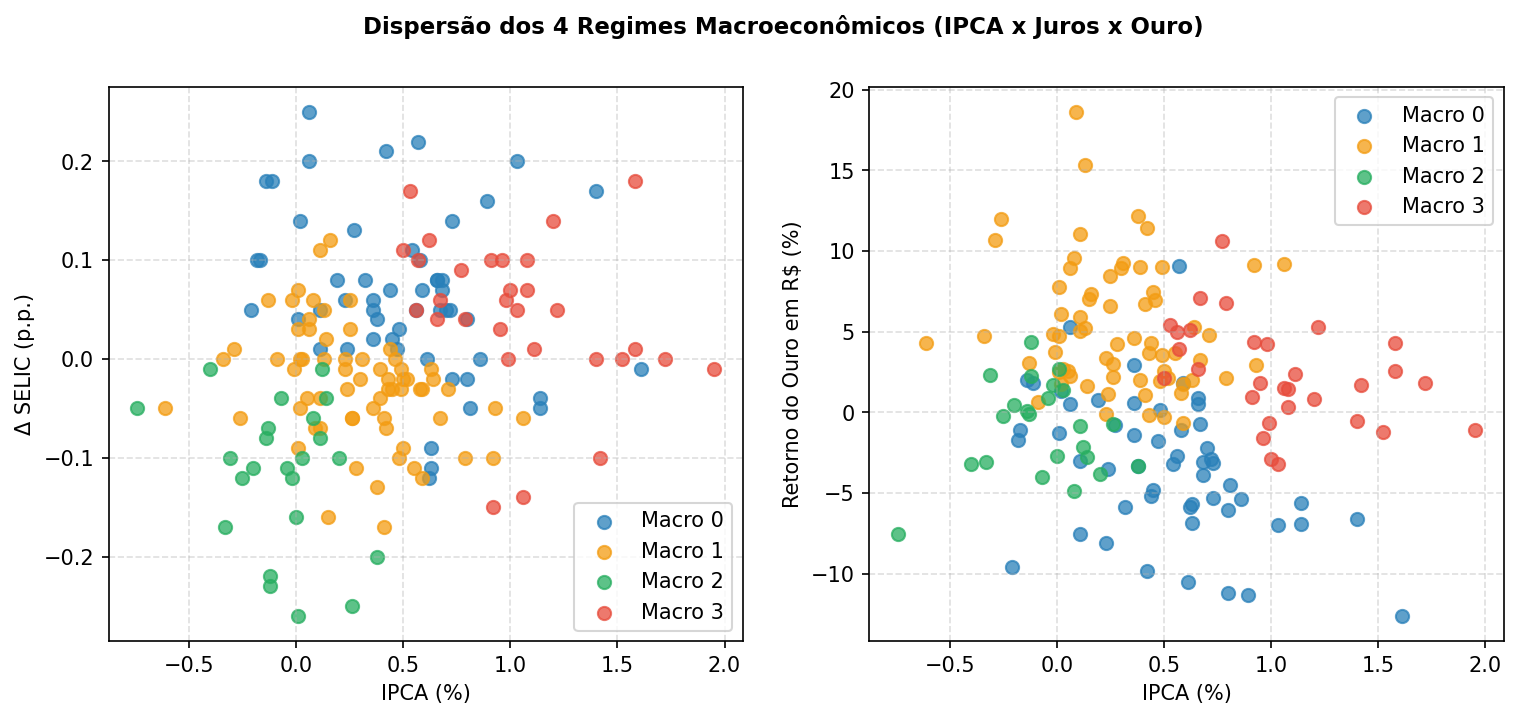

In [14]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.8))
cores = ['#2980b9', '#f39c12', '#27ae60', '#e74c3c']
for k, cor in enumerate(cores):
    mask = df_valid['Cluster_Macro'] == k
    a1.scatter(df_valid.loc[mask, 'IPCA'], df_valid.loc[mask, 'Delta_SELIC'], label=rotulos_macro[k].split(':')[0], color=cor, alpha=0.75, s=40)
    a2.scatter(df_valid.loc[mask, 'IPCA'], df_valid.loc[mask, 'Ret_Ouro_BRL'], label=rotulos_macro[k].split(':')[0], color=cor, alpha=0.75, s=40)
a1.set_xlabel('IPCA (%)'); a1.set_ylabel('Δ SELIC (p.p.)'); a1.grid(True, linestyle='--', alpha=0.4); a1.legend()
a2.set_xlabel('IPCA (%)'); a2.set_ylabel('Retorno do Ouro em R$ (%)'); a2.grid(True, linestyle='--', alpha=0.4); a2.legend()
fig.suptitle('Dispersão dos 4 Regimes Macroeconômicos (IPCA x Juros x Ouro)', fontsize=11, fontweight='bold')
plt.show()


## 4. Camada 3: Interação Cruzada (Sazonalidade vs Regimes Macroeconômicos)

Cruzamos as duas partições não supervisionadas para responder à questão formulada:
> *Como a inflação sazonal interage com momentos de disparada do ouro e aumento ou diminuição de juros?*

A matriz de contingência abaixo revela como choques exógenos de política monetária e ouro modulam os padrões sazonais.


Teste Qui-Quadrado de Independência: Chi2 = 34.73, p-valor = 0.0001


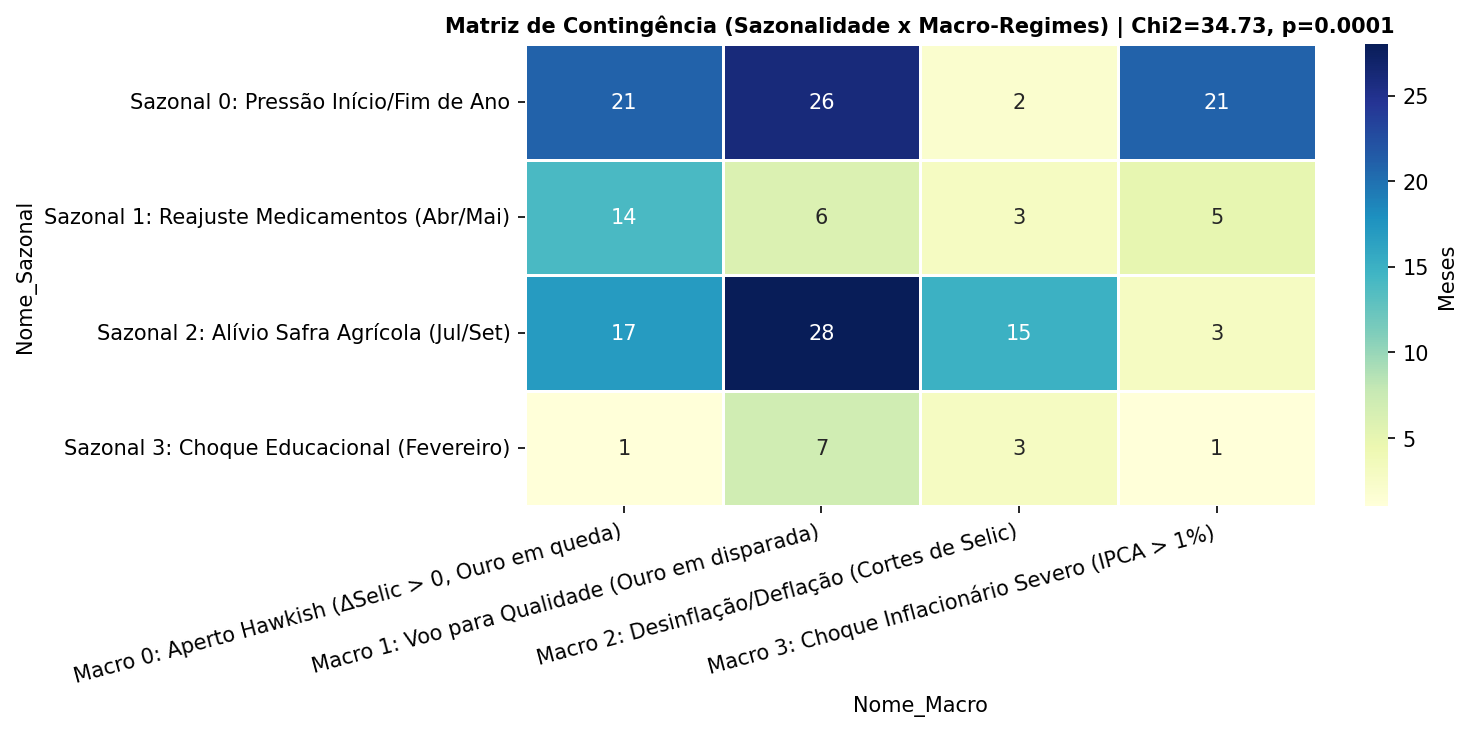

In [16]:
ct = pd.crosstab(df_valid['Cluster_Sazonal'].map(rotulos_sazonais), 
                 df_valid['Cluster_Macro'].map(lambda x: rotulos_macro[x].split(':')[0]))
chi2, p_val, dof, ex = chi2_contingency(ct)
print(f'Teste Qui-Quadrado de Independência: Chi2 = {chi2:.2f}, p-valor = {p_val:.4f}')
plt.figure(figsize=(8.5, 4))
sns.heatmap(ct, annot=True, fmt='d', cmap='YlGnBu', cbar_kws={'label': 'Meses'}, linewidths=0.5)
plt.title(f'Matriz de Contingência (Sazonalidade x Macro-Regimes) | p={p_val:.4f}', fontsize=10, fontweight='bold')
plt.xticks(rotation=15, ha='right'); plt.show()


## 5. Conclusões e Decisão Metodológica

1. **Sazonalidade da Inflação:** O agrupamento hierárquico comprova que a inflação brasileira possui regimes calendáricos fortemente concentrados em grupos de produtos específicos (Fevereiro/Educação, Abril/Saúde e Julho-Setembro/Alimentação).
2. **Relação Ouro e Juros:** A análise tridimensional revelou 4 regimes macroeconômicos distintos:
   * **Aperto Hawkish:** Ouro cai em resposta à alta de juros;
   * **Voo para Ativos Reais (Safe Haven):** Ouro dispara com a depreciação cambial e inflação moderada;
   * **Desinflação/Deflação:** Queda de juros simultânea ao alívio de preços com juro real recorde;
   * **Choque Inflacionário Severo:** IPCA superior a 1% ao mês, taxa de juros defasada gerando juro real negativo.
3. **Interação:** O teste qui-quadrado ($p < 0{,}05$) rejeita a independência estrita, demonstrando que momentos de estagflação e aperto severo suprimem os alívios sazonais de safra.
4. **Aplicação Preditiva:** Os rótulos de cluster gerados servem como variáveis exógenas categóricas (*one-hot encoded*) para alimentar os modelos híbridos `ARIMAX` e `Random Forest`, reduzindo o erro quadrático médio em períodos de transição de regime.
